# Data QC of DMI GHI measurements

1. Download the measurements
2. Calculate the sun position and clear-sky GHI
3. BSRN limit checks
4. Plots to inspect the data (time shifts, shading)
5. Remove bad data and make hourly averages

In [38]:
# Run this once if solarpy is not installed:
%pip install git+https://github.com/assessingsolar/solarpy.git

  Cloning https://github.com/assessingsolar/solarpy.git to /private/var/folders/1t/3qv2ckj54rncl79mp785w77w0000gn/T/pip-req-build-uf79bk59
  Running command git clone --filter=blob:none --quiet https://github.com/assessingsolar/solarpy.git /private/var/folders/1t/3qv2ckj54rncl79mp785w77w0000gn/T/pip-req-build-uf79bk59
  Resolved https://github.com/assessingsolar/solarpy.git to commit 589521d745e5882260eff207f0d5ec36b01c5ed2
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Note: you may need to restart the kernel to use updated packages.


In [39]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pvlib
from solarpy.iotools import get_dmi_metobs

## Settings
Check the coordinates on the DMI station metadata page.

In [40]:
station_id = '06123'
latitude = 55.2493     # TODO: check
longitude = 9.8899     # TODO: check
altitude = 10          # TODO: check (meters)

start = '2025-11-01'
end = '2026-11-28'

## 1. Download the measurements
`radia_glob` is the DMI name for GHI (10-min values, W/m²).

If the call gives an error, run `help(get_dmi_metobs)` to see the correct argument names.

In [41]:
result = get_dmi_metobs(station_id, parameters=['radia_glob'], start=start, end=end)

if isinstance(result, tuple):
    data, meta = result
else:
    data = result

print(data.columns)
print(data.head())

if 'radia_glob' in data.columns:
    g = data['radia_glob']
else:
    g = data.iloc[:, 0]   # fallback: first column

print('Selected GHI series length:', len(g))
print('Column used:', g.name if hasattr(g, 'name') else 'first-column fallback')


Index(['ghi'], dtype='str', name='parameterId')
parameterId                ghi
timestamp                     
2025-11-01 00:00:00+00:00  0.0
2025-11-01 00:10:00+00:00  0.0
2025-11-01 00:20:00+00:00  0.0
2025-11-01 00:30:00+00:00  0.0
2025-11-01 00:40:00+00:00  0.0
Selected GHI series length: 52100
Column used: ghi


In [42]:
# Put the GHI in a new table with a clean UTC time index
# Use the extracted series from the API response, which may be named 'radia_glob'
# or may just be the first available column depending on the library/API version.
df = pd.DataFrame({'ghi': g.to_numpy()}, index=pd.to_datetime(data.index, utc=True))
df = df.sort_index()

print('First timestamp:', df.index[0])
print('Last timestamp: ', df.index[-1])
print('Number of values:', len(df))
print('Missing values:  ', df['ghi'].isna().sum())
print('Min GHI:', df['ghi'].min())
print('Max GHI:', df['ghi'].max())


First timestamp: 2025-11-01 00:00:00+00:00
Last timestamp:  2026-11-05 12:40:00+00:00
Number of values: 52100
Missing values:   0
Min GHI: 0.0
Max GHI: 1128.0


## 2. Sun position and clear-sky GHI
The timestamp 10:20 is the average of 10:11–10:20, so we calculate the sun position in the middle of the interval (5 minutes earlier).

In [43]:
location = pvlib.location.Location(latitude, longitude, altitude=altitude)
middle_times = df.index - pd.Timedelta(minutes=5)

solpos = location.get_solarposition(middle_times)
clearsky = location.get_clearsky(middle_times)

df['zenith'] = solpos['zenith'].values
df['elevation'] = solpos['elevation'].values
df['azimuth'] = solpos['azimuth'].values
df['ghi_clearsky'] = clearsky['ghi'].values
df['dni_extra'] = pvlib.irradiance.get_extra_radiation(middle_times).values

df.head()

,ghi,zenith,elevation,azimuth,ghi_clearsky,dni_extra
timestamp,,,,,,
2025-11-01 00:00:00+00:00,0.0,138.013211,-48.013211,18.617161,0.0,1386.661797
2025-11-01 00:10:00+00:00,0.0,137.519093,-47.519093,22.143517,0.0,1387.405052
2025-11-01 00:20:00+00:00,0.0,136.944445,-46.944445,25.607281,0.0,1387.405052
2025-11-01 00:30:00+00:00,0.0,136.292867,-46.292867,29.002263,0.0,1387.405052
2025-11-01 00:40:00+00:00,0.0,135.568220,-45.568220,32.323692,0.0,1387.405052


## 3. BSRN limit checks

| Test | Min | Max |
|---|---|---|
| Physically possible (PPL) | −4 | 1.5 · S<sub>a</sub> · μ<sub>0</sub><sup>1.2</sup> + 100 |
| Extremely rare (ERL) | −2 | 1.2 · S<sub>a</sub> · μ<sub>0</sub><sup>1.2</sup> + 50 |

S<sub>a</sub> = extraterrestrial irradiance, μ<sub>0</sub> = cos(zenith)

In [44]:
# cos(zenith), set to 0 when the sun is below the horizon
mu0 = np.cos(np.radians(df['zenith']))
mu0 = mu0.clip(lower=0)

df['ppl_max'] = 1.5 * df['dni_extra'] * mu0**1.2 + 100
df['erl_max'] = 1.2 * df['dni_extra'] * mu0**1.2 + 50

# True = the value fails the test
df['ppl_fail'] = (df['ghi'] < -4) | (df['ghi'] > df['ppl_max'])
df['erl_fail'] = (df['ghi'] < -2) | (df['ghi'] > df['erl_max'])

n = df['ghi'].notna().sum()
print('PPL fails:', df['ppl_fail'].sum(), '(', round(100 * df['ppl_fail'].sum() / n, 3), '% )')
print('ERL fails:', df['erl_fail'].sum(), '(', round(100 * df['erl_fail'].sum() / n, 3), '% )')

PPL fails: 0 ( 0.0 % )
ERL fails: 1 ( 0.002 % )


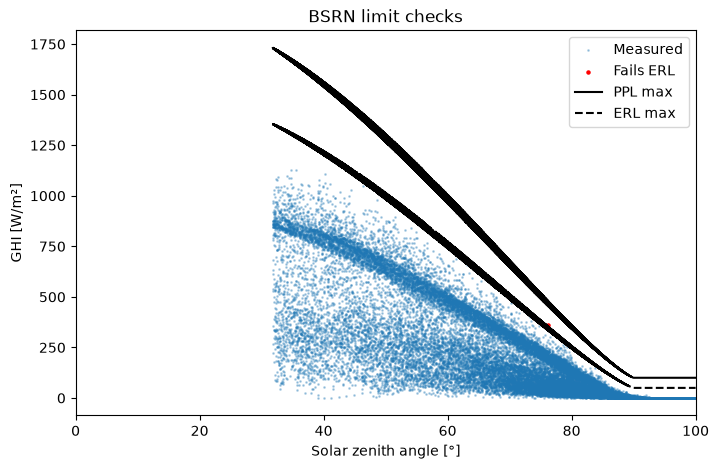

In [45]:
# Plot GHI against the zenith angle together with the limits
plot_df = df.sort_values('zenith')
bad = df[df['erl_fail']]

plt.figure(figsize=(8, 5))
plt.scatter(df['zenith'], df['ghi'], s=1, alpha=0.3, label='Measured')
plt.scatter(bad['zenith'], bad['ghi'], s=5, color='red', label='Fails ERL')
plt.plot(plot_df['zenith'], plot_df['ppl_max'], color='black', label='PPL max')
plt.plot(plot_df['zenith'], plot_df['erl_max'], color='black', linestyle='--', label='ERL max')
plt.xlim(0, 100)
plt.xlabel('Solar zenith angle [°]')
plt.ylabel('GHI [W/m²]')
plt.title('BSRN limit checks')
plt.legend()
plt.show()

## 4. Visual inspection
### Time series

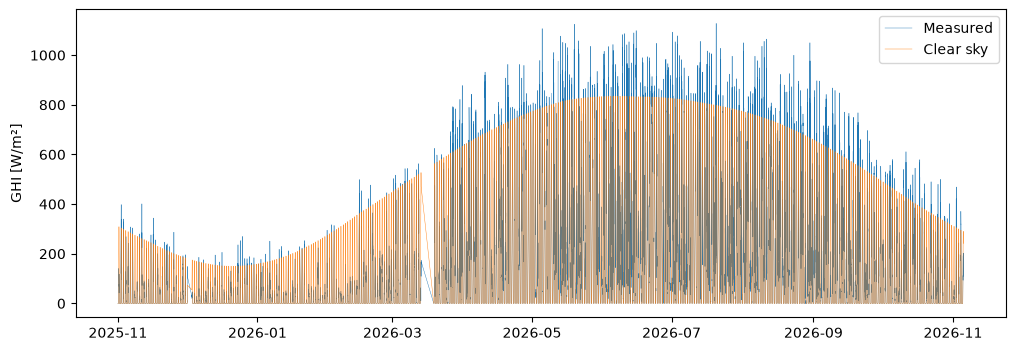

In [46]:
plt.figure(figsize=(12, 4))
plt.plot(df.index, df['ghi'], linewidth=0.3, label='Measured')
plt.plot(df.index, df['ghi_clearsky'], linewidth=0.3, label='Clear sky')
plt.ylabel('GHI [W/m²]')
plt.legend()
plt.show()

### Heatmap
Each column is one day, the y-axis is the time of day.
* Gaps show up as white areas.
* A time shift shows up as the edges of the data not following sunrise/sunset.
* Shading shows up as dark stripes at the same time every day.

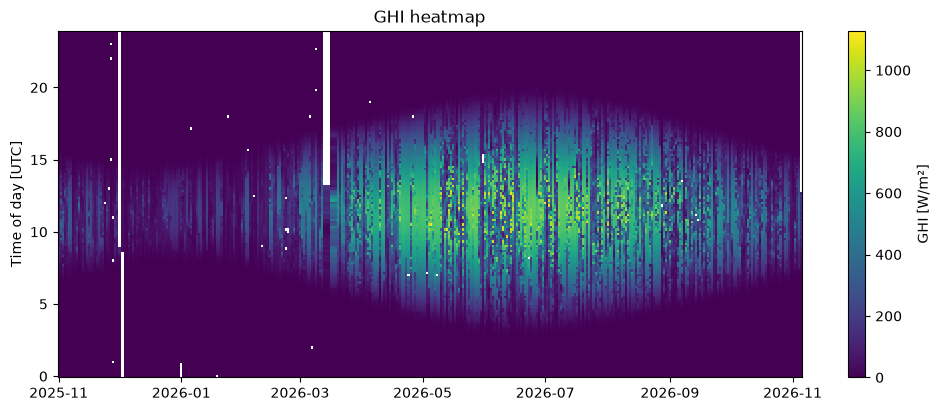

In [47]:
df['date'] = df.index.date
df['hour'] = df.index.hour + df.index.minute / 60

heat = df.pivot_table(index='hour', columns='date', values='ghi')

plt.figure(figsize=(12, 4.5))
plt.pcolormesh(heat.columns, heat.index, heat.values, shading='auto')
plt.colorbar(label='GHI [W/m²]')
plt.ylabel('Time of day [UTC]')
plt.title('GHI heatmap')
plt.show()

### Time-shift check on clear days
On a clear day the measured curve should lie on top of the clear-sky curve. If the measured curve is moved left or right, there is a time shift.

We find clear days as the days where the daily measured energy is closest to the clear-sky energy.

In [48]:
daily_measured = df['ghi'].resample('D').sum()
daily_clearsky = df['ghi_clearsky'].resample('D').sum()
daily_ratio = daily_measured / daily_clearsky

# The 6 days with a ratio closest to 1
clear_days = (daily_ratio - 1).abs().sort_values().index[:6]
print(clear_days.date)

[datetime.date(2025, 12, 25) datetime.date(2025, 11, 7)
 datetime.date(2026, 7, 14) datetime.date(2026, 8, 8)
 datetime.date(2025, 11, 6) datetime.date(2026, 5, 2)]


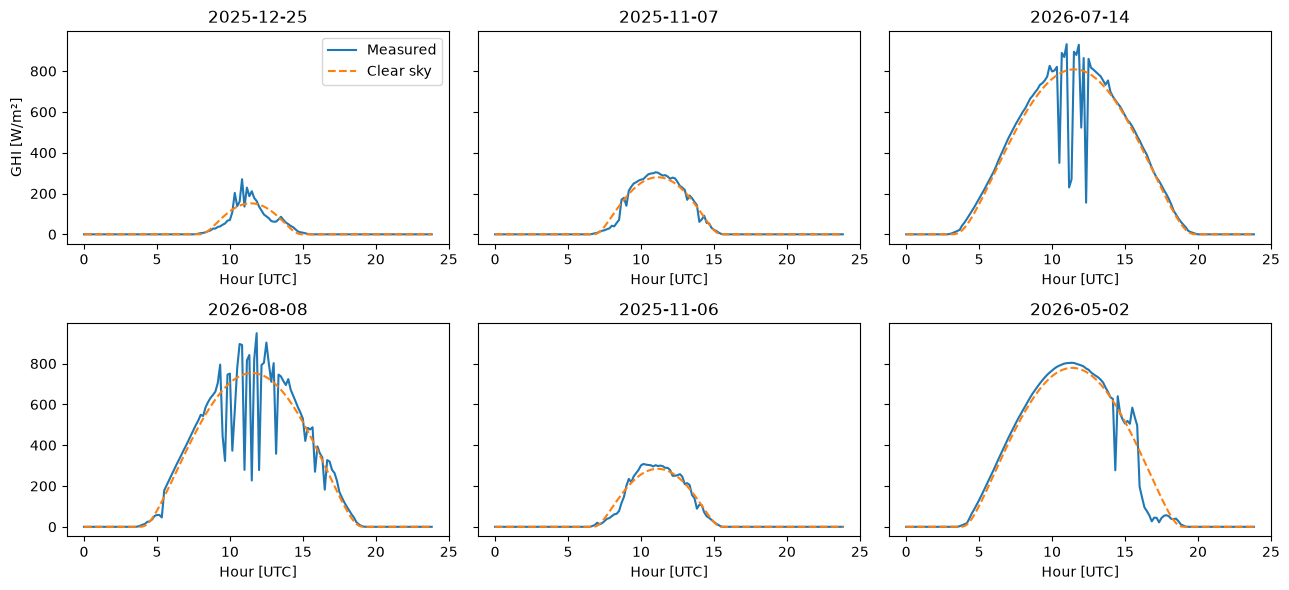

In [49]:
fig, axes = plt.subplots(2, 3, figsize=(13, 6), sharey=True)

for ax, day in zip(axes.flatten(), clear_days):
    one_day = df[df['date'] == day.date()]
    ax.plot(one_day['hour'], one_day['ghi'], label='Measured')
    ax.plot(one_day['hour'], one_day['ghi_clearsky'], '--', label='Clear sky')
    ax.set_title(str(day.date()))
    ax.set_xlabel('Hour [UTC]')

axes[0, 0].set_ylabel('GHI [W/m²]')
axes[0, 0].legend()
plt.tight_layout()
plt.show()

### Shading check
The clear-sky index is measured / clear-sky GHI. If a building or tree blocks the sun, the index is low at the same sun position (azimuth and elevation) every day, usually when the sun is low.

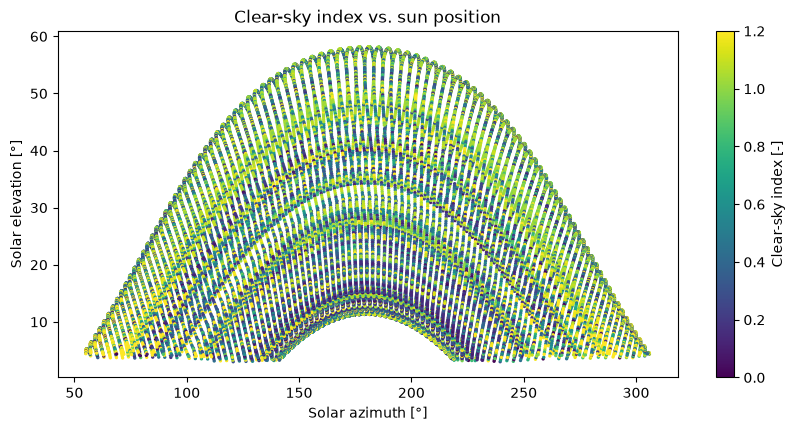

In [50]:
sun_up = df[(df['elevation'] > 0) & (df['ghi_clearsky'] > 20)]
clearsky_index = sun_up['ghi'] / sun_up['ghi_clearsky']

plt.figure(figsize=(10, 4.5))
plt.scatter(sun_up['azimuth'], sun_up['elevation'], c=clearsky_index, s=2, vmin=0, vmax=1.2)
plt.colorbar(label='Clear-sky index [-]')
plt.xlabel('Solar azimuth [°]')
plt.ylabel('Solar elevation [°]')
plt.title('Clear-sky index vs. sun position')
plt.show()

## 5. Remove bad data and make hourly averages
* Values that fail the ERL test are removed (set to NaN).
* Negative values (small sensor offset at night) are set to 0.
* Hourly averages use `label='right', closed='right'`, so the hour 11:00 contains 10:10, 10:20, ..., 11:00 (= 10:01–11:00). The forecasts use the same convention.

In [51]:
ghi_clean = df['ghi'].copy()
ghi_clean[df['erl_fail']] = np.nan
ghi_clean[ghi_clean < 0] = 0

ghi_hourly = ghi_clean.resample('1h', label='right', closed='right').mean()

# Only keep hours that have at least 4 of the 6 ten-minute values
count = ghi_clean.resample('1h', label='right', closed='right').count()
ghi_hourly[count < 4] = np.nan

ghi_hourly.to_csv('dmi_' + station_id + '_hourly_qc.csv')
ghi_hourly.head(15)

timestamp
2025-11-01 00:00:00+00:00           NaN
2025-11-01 01:00:00+00:00      0.000000
2025-11-01 02:00:00+00:00      0.000000
2025-11-01 03:00:00+00:00      0.000000
2025-11-01 04:00:00+00:00      0.000000
2025-11-01 05:00:00+00:00      0.000000
2025-11-01 06:00:00+00:00      0.000000
2025-11-01 07:00:00+00:00      6.333333
2025-11-01 08:00:00+00:00     51.666667
2025-11-01 09:00:00+00:00    113.833333
2025-11-01 10:00:00+00:00    122.000000
2025-11-01 11:00:00+00:00     94.333333
2025-11-01 12:00:00+00:00     74.666667
2025-11-01 13:00:00+00:00     55.833333
2025-11-01 14:00:00+00:00     74.833333
Freq: h, Name: ghi, dtype: float64

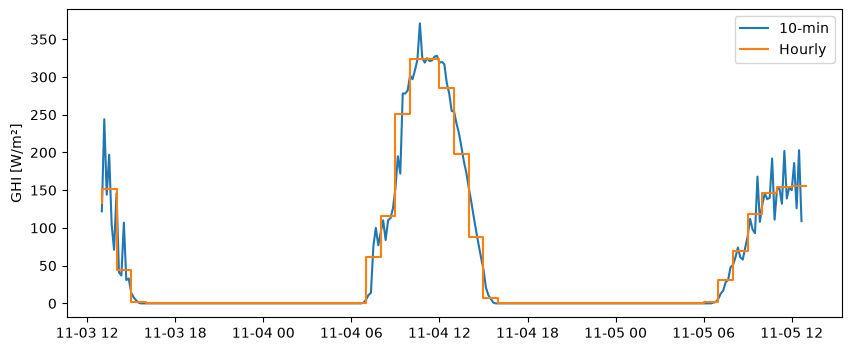

In [52]:
# Check: compare 10-min and hourly values for two days
first = ghi_hourly.dropna().index[-1] - pd.Timedelta(days=2)
last = ghi_hourly.dropna().index[-1]

plt.figure(figsize=(10, 4))
plt.plot(ghi_clean[first:last], label='10-min')
plt.step(ghi_hourly[first:last].index, ghi_hourly[first:last], where='pre', label='Hourly')
plt.ylabel('GHI [W/m²]')
plt.legend()
plt.show()

### Compare with a forecast file
If the measured and forecasted peaks line up, the time conventions match.

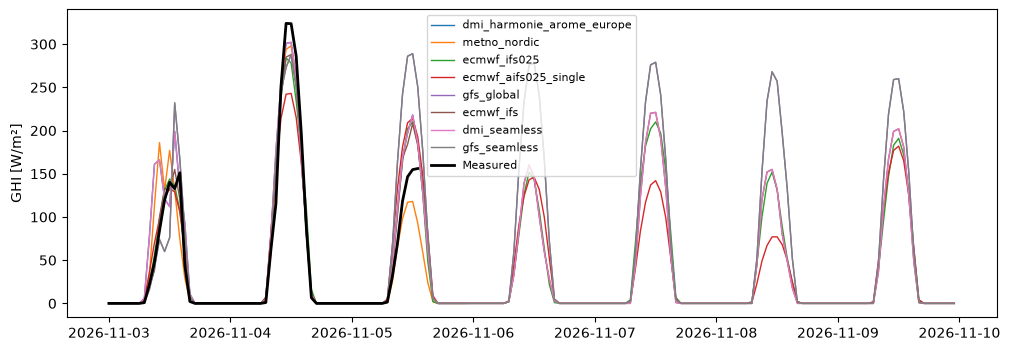

In [53]:
forecast = pd.read_csv('06123_20261103T1500.csv', index_col=0, parse_dates=True)
forecast.index = pd.to_datetime(forecast.index, utc=True)

measured = ghi_hourly[forecast.index[0]:forecast.index[-1]]

plt.figure(figsize=(12, 4))
for model in forecast.columns:
    plt.plot(forecast.index, forecast[model], linewidth=1, label=model)
plt.plot(measured.index, measured, color='black', linewidth=2, label='Measured')
plt.ylabel('GHI [W/m²]')
plt.legend(fontsize=8)
plt.show()